In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt

In [2]:
alpha = 0.1
gamma = 0.95
epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.995
episodes = 20000
Q = {}

In [3]:
def new_board():
    return [" "] * 9

def display_board(board):
    for i in range(0, 9, 3):
        print("|".join(board[i:i + 3]))
        if i < 6:
            print("-----")

def check_winner(board, player):
    wins = [
        (0, 1, 2), (3, 4, 5), (6, 7, 8),
        (0, 3, 6), (1, 4, 7), (2, 5, 8),
        (0, 4, 8), (2, 4, 6)
    ]
    return any(board[a] == board[b] == board[c] == player for a, b, c in wins)

def is_draw(board):
    return " " not in board

def get_state(board):
    return "".join(board)

def get_q_values(state):
    if state not in Q:
        Q[state] = np.zeros(9)
    return Q[state]

def choose_action(board, exploration_rate):
    state = get_state(board)
    q_values = get_q_values(state)
    available = [i for i in range(9) if board[i] == " "]
    if not available:
        return None
    if random.random() < exploration_rate:
        return random.choice(available)
    best_value = max(q_values[i] for i in available)
    best_actions = [i for i in available if q_values[i] == best_value]
    return random.choice(best_actions)

In [4]:
def opponent_move(board):
    available = [i for i in range(9) if board[i] == " "]
    return random.choice(available) if available else None

In [5]:
rewards_history = []
win_history = []
draw_history = []
loss_history = []

In [6]:
for episode in range(episodes):
    board = new_board()
    episode_reward = 0
    while True:
        state = get_state(board)
        action = choose_action(board, epsilon)
        board[action] = "X"
        if check_winner(board, "X"):
            reward = 1
            old_q = get_q_values(state)[action]
            Q[state][action] = old_q + alpha * (reward - old_q)
            episode_reward = 1
            win_history.append(1)
            draw_history.append(0)
            loss_history.append(0)
            break
        if is_draw(board):
            episode_reward = 0.5
            win_history.append(0)
            draw_history.append(1)
            loss_history.append(0)
            break
        opponent_action = opponent_move(board)
        board[opponent_action] = "O"
        if check_winner(board, "O"):
            reward = -1
            old_q = get_q_values(state)[action]
            Q[state][action] = old_q + alpha * (reward - old_q)
            episode_reward = -1
            win_history.append(0)
            draw_history.append(0)
            loss_history.append(1)
            break
        if is_draw(board):
            episode_reward = 0.5
            win_history.append(0)
            draw_history.append(1)
            loss_history.append(0)
            break
        next_state = get_state(board)
        next_q = get_q_values(next_state)
        old_q = get_q_values(state)[action]
        available_next = [i for i in range(9) if board[i] == " "]
        target = -0.01 + gamma * max(next_q[i] for i in available_next)
        Q[state][action] = old_q + alpha * (target - old_q)
    rewards_history.append(episode_reward)
    epsilon = max(epsilon_min, epsilon * epsilon_decay)
print("Training completed.")
print("Q-table states:", len(Q))

Training completed.
Q-table states: 1637


In [7]:
def evaluate_agent(test_episodes=1000):
    wins = draws = losses = 0
    for _ in range(test_episodes):
        board = new_board()
        while True:
            state = get_state(board)
            available = [i for i in range(9) if board[i] == " "]
            q_values = get_q_values(state)
            best_value = max(q_values[i] for i in available)
            best_actions = [i for i in available if q_values[i] == best_value]
            action = random.choice(best_actions)
            board[action] = "X"
            if check_winner(board, "X"):
                wins += 1
                break
            if is_draw(board):
                draws += 1
                break
            opponent_action = opponent_move(board)
            board[opponent_action] = "O"
            if check_winner(board, "O"):
                losses += 1
                break
            if is_draw(board):
                draws += 1
                break
    total = wins + draws + losses
    return wins / total * 100, draws / total * 100, losses / total * 100

In [8]:
win_rate, draw_rate, loss_rate = evaluate_agent()
print("Q-LEARNING TIC-TAC-TOE RESULTS")
print("------------------------------")
print("Training episodes:", episodes)
print("Final epsilon:", round(epsilon, 3))
print("Win rate:", round(win_rate, 2), "%")
print("Draw rate:", round(draw_rate, 2), "%")
print("Loss rate:", round(loss_rate, 2), "%")

Q-LEARNING TIC-TAC-TOE RESULTS
------------------------------
Training episodes: 20000
Final epsilon: 0.05
Win rate: 95.6 %
Draw rate: 3.5 %
Loss rate: 0.9 %


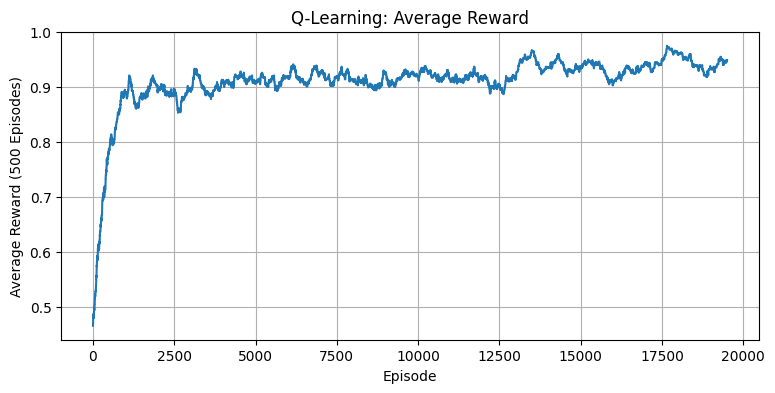

In [9]:
window = 500
avg_rewards = np.convolve(rewards_history, np.ones(window) / window, mode="valid")
plt.figure(figsize=(9, 4))
plt.plot(avg_rewards)
plt.title("Q-Learning: Average Reward")
plt.xlabel("Episode")
plt.ylabel("Average Reward (500 Episodes)")
plt.grid(True)
plt.show()

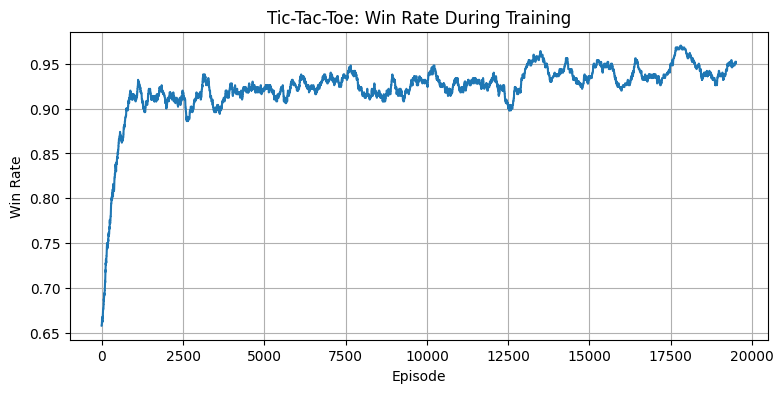

In [10]:
win_rates = np.convolve(win_history, np.ones(window) / window, mode="valid")
plt.figure(figsize=(9, 4))
plt.plot(win_rates)
plt.title("Tic-Tac-Toe: Win Rate During Training")
plt.xlabel("Episode")
plt.ylabel("Win Rate")
plt.grid(True)
plt.show()